# CIFAR-10 profiling & debugging - SageMaker SDK v3

SageMaker Debugger/Profiler can't be attached to `ModelTrainer`, so this notebook uses:
- **TensorBoard** (losses, gradients, weight histograms, torch.profiler trace)
- an in-script **system monitor** (CPU/GPU/memory every 500 ms)
- in-script **rules** (LossNotDecreasing, VanishingGradient, Overfit, Overtraining, + profiler checks)

All results come back in `output.tar.gz`.

In [3]:
# with open(f"{source_dir}/requirements.txt", "w") as f:
#     f.write("protobuf==3.20.3\ntensorboard\npsutil\n")

In [4]:
!python -m py_compile scripts/pytorch_cifar_profiling.py && echo "OK"

OK


In [5]:
# Restart the kernel afterwards
!pip install -U "sagemaker>=3.0" pandas matplotlib tensorboard

  Using cached pandas-3.0.6-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)


In [6]:
hyperparameters = {
    "batch_size": 2048,
    "gpu": True,
    "epoch": 2,
    "model": "resnet50",
}

In [7]:
import os
import boto3
from sagemaker.core.helper.session_helper import Session, get_execution_role

sagemaker_session = Session()
role = get_execution_role()
region = boto3.session.Session().region_name
bucket = sagemaker_session.default_bucket()

output_s3 = f"s3://{bucket}/course3/lesson3/fine-tuned-models"
tensorboard_s3 = f"{output_s3}/course3/lesson3/tensorboard"

source_dir = "scripts"
assert os.path.exists(f"{source_dir}/pytorch_cifar_profiling.py"), "expected scripts/pytorch_cifar_profiling.py"

# smdebug is no longer needed; tensorboard + psutil are
with open(f"{source_dir}/requirements.txt", "w") as f:
    f.write("tensorboard\npsutil\n")

training_image = f"763104351884.dkr.ecr.{region}.amazonaws.com/pytorch-training:1.13.1-gpu-py39"

print(role)
print(output_s3)
print(training_image)

arn:aws:iam::950885994135:role/service-role/AmazonSageMaker-ExecutionRole-20261013T173018
s3://sagemaker-us-east-1-950885994135/course3/lesson3/fine-tuned-models
763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:1.13.1-gpu-py39


In [8]:
from sagemaker.train import ModelTrainer
from sagemaker.core.training.configs import (
    Compute,
    InputData,
    OutputDataConfig,
    SourceCode,
    StoppingCondition,
)

# command = "python pytorch_cifar_profiling.py " + " ".join(f"--{k} {v}" for k, v in hyperparameters.items())   # ai slop

trainer = ModelTrainer(
    training_image=training_image,
    role=role,
    sagemaker_session=sagemaker_session,
    base_job_name="cifar-profiling-sagemaker-v3",
    source_code=SourceCode(
        source_dir=source_dir,
        requirements="requirements.txt",
        # command=command,
        entry_script="pytorch_cifar_profiling.py"
    ),
    compute=Compute(instance_type="ml.g4dn.xlarge", instance_count=1),
    output_data_config=OutputDataConfig(s3_output_path=output_s3),
    hyperparameters=hyperparameters,
    stopping_condition=StoppingCondition(max_runtime_in_seconds=900),
)

# Optional: live upload of TensorBoard logs to S3 (needed for the SageMaker TensorBoard app).
# Not required: the logs are also inside output.tar.gz.
try:
    from sagemaker.core.shapes import TensorBoardOutputConfig
    trainer = trainer.with_tensorboard_output_config(
        TensorBoardOutputConfig(s3_output_path=tensorboard_s3, local_path="/opt/ml/output/tensorboard")
    )
    print("TensorBoardOutputConfig attached ->", tensorboard_s3)
except Exception as e:
    print("TensorBoardOutputConfig not attached (fine, logs are in output.tar.gz):", e)


# #####################
# estimator = ModelTrainer(
#     training_image=image_uris.retrieve(
#         framework="pytorch",
#         region=region,
#         version="2.1",
#         py_version="py310",
#         instance_type=INSTANCE_TYPE,
#         image_scope="training",
#     ),
#     source_code=SourceCode(
#         source_dir="scripts",              # relative to this file (project root)
#         entry_script="pytorch_cifar.py",   # relative to source_dir
#     ),
#     role=role,
#     compute=Compute(
#         instance_type=INSTANCE_TYPE,
#         instance_count=1,
#         volume_size_in_gb=10,
#     ),
#     output_data_config=OutputDataConfig(
#         s3_output_path=f"s3://{bucket}/cifar10-script-mode/output",
#     ),
#     stopping_condition=StoppingCondition(max_runtime_in_seconds=900),
#     hyperparameters=hyperparameters,
#     base_job_name="pytorch-cifar10",
# )
# ################################

TensorBoardOutputConfig attached -> s3://sagemaker-us-east-1-950885994135/course3/lesson3/fine-tuned-models/course3/lesson3/tensorboard


In [9]:
trainer.train(
    input_data_config=[
        InputData(channel_name="training", data_source=f"s3://{bucket}/course3/lesson3/cifar10/data/")
    ],
    wait=True
)

Output()

In [10]:
training_job_name = trainer._latest_training_job.training_job_name
print(f"Training job name: {training_job_name}")

sm_client = boto3.client("sagemaker", region_name=region)
job_description = sm_client.describe_training_job(TrainingJobName=training_job_name)

# output.tar.gz sits next to model.tar.gz
model_artifacts = job_description["ModelArtifacts"]["S3ModelArtifacts"]
output_tar = model_artifacts.replace("model.tar.gz", "output.tar.gz")  # The output.tar.gz is in the same location as model.tar.gz
print(output_tar)

Training job name: cifar-profiling-sagemaker-v3-20261017094549
s3://sagemaker-us-east-1-950885994135/course3/lesson3/fine-tuned-models/cifar-profiling-sagemaker-v3-20261017094549/output/output.tar.gz


In [11]:
# Replaces create_trial(...): download and extract everything the script produced
local_dir = f"./job_output/{training_job_name}"
os.makedirs(local_dir, exist_ok=True)
!aws s3 cp {output_tar} {local_dir}/output.tar.gz
!tar -xzf {local_dir}/output.tar.gz -C {local_dir}
!ls -R {local_dir} | head -40

download: s3://sagemaker-us-east-1-950885994135/course3/lesson3/fine-tuned-models/cifar-profiling-sagemaker-v3-20261017094549/output/output.tar.gz to job_output/cifar-profiling-sagemaker-v3-20261017094549/output.tar.gz
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
./job_output/cifar-profiling-sagemaker-v3-20261017094549:
met

## Debugger equivalent: tracked losses and gradients

In [22]:
output_path = trainer.output_data_config.s3_output_path.rstrip("/")
job_prefix = f"{output_path}/{training_job_name}/"
print(job_prefix)

s3://sagemaker-us-east-1-950885994135/course3/lesson3/fine-tuned-models/cifar-profiling-sagemaker-v3-20261017094549/


In [23]:
!aws s3 ls "$job_prefix" --recursive

2026-10-17 09:52:29   95470446 course3/lesson3/fine-tuned-models/cifar-profiling-sagemaker-v3-20261017094549/output/model.tar.gz
2026-10-17 09:52:32    9123114 course3/lesson3/fine-tuned-models/cifar-profiling-sagemaker-v3-20261017094549/output/output.tar.gz


datapoints in TRAIN mode: 50
datapoints in EVAL mode : 10


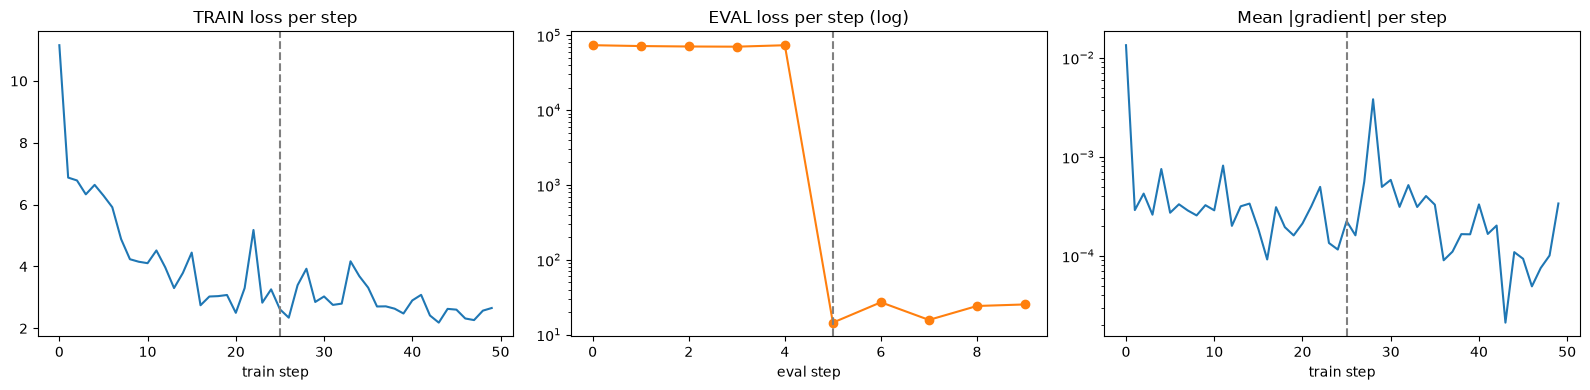

mode,EVAL,TRAIN
epoch,,
0,72085.679688,4.655637
1,21.351633,2.842482


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.read_csv(f"{local_dir}/metrics.csv")
metrics["mean_abs_grad"] = pd.to_numeric(metrics["mean_abs_grad"], errors="coerce")  # EVAL rows are empty

tr = metrics[metrics["mode"] == "TRAIN"]
ev = metrics[metrics["mode"] == "EVAL"]
print("datapoints in TRAIN mode:", len(tr))
print("datapoints in EVAL mode :", len(ev))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1. TRAIN loss on its own axis
ax[0].plot(tr["step"], tr["loss"])
ax[0].set_title("TRAIN loss per step"); ax[0].set_xlabel("train step")

# 2. EVAL loss on a log scale (values range from ~25 to ~70,000)
ax[1].plot(ev["step"], ev["loss"], marker="o", color="tab:orange")
ax[1].set_yscale("log"); ax[1].set_title("EVAL loss per step (log)"); ax[1].set_xlabel("eval step")

# 3. Gradients
ax[2].plot(tr["step"], tr["mean_abs_grad"])
ax[2].set_yscale("log"); ax[2].set_title("Mean |gradient| per step"); ax[2].set_xlabel("train step")

# Epoch boundaries
for e in range(1, metrics["epoch"].max() + 1):
    ax[0].axvline(tr[tr["epoch"] == e]["step"].min(), ls="--", c="grey")
    ax[1].axvline(ev[ev["epoch"] == e]["step"].min(), ls="--", c="grey")
    ax[2].axvline(tr[tr["epoch"] == e]["step"].min(), ls="--", c="grey")

plt.tight_layout(); plt.show()

# Per-epoch comparison: this is the fair TRAIN vs EVAL view
metrics.groupby(["epoch", "mode"])["loss"].mean().unstack()

## Profiler equivalent: system timeline (replaces TimelineCharts)

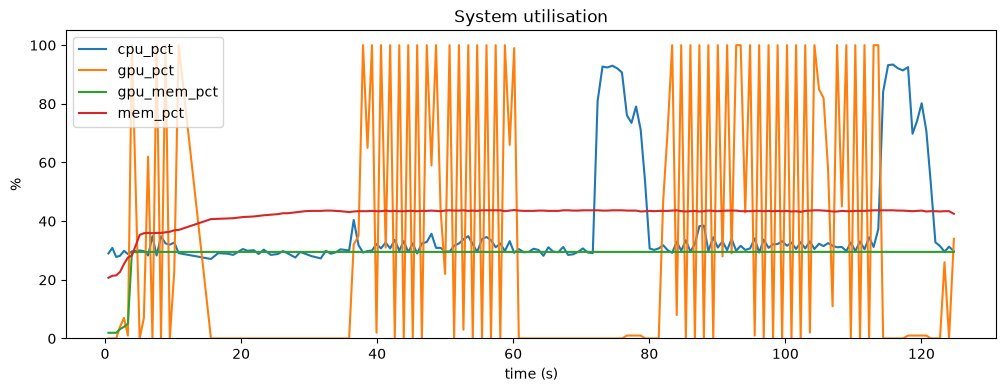

,time_s,cpu_pct,mem_pct,gpu_pct,gpu_mem_pct
mean,65.502339,37.502924,42.120468,31.818713,28.586326
50%,66.610000,30.900000,43.500000,0.000000,29.511719
max,124.770000,93.400000,43.800000,100.000000,29.524740


In [13]:
sysm = pd.read_csv(f"{local_dir}/system_metrics.csv")
fig, ax = plt.subplots(figsize=(12, 4))
for col in ["cpu_pct", "gpu_pct", "gpu_mem_pct", "mem_pct"]:
    if sysm[col].notna().any():
        ax.plot(sysm["time_s"], sysm[col], label=col)
ax.set_xlabel("time (s)"); ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.legend(); ax.set_title("System utilisation")
plt.show()
sysm.describe().loc[["mean", "50%", "max"]]

In [14]:
# Framework profiling: top operators (from torch.profiler)
print(open(f"{local_dir}/torch_profiler_summary.txt").read())

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
autograd::engine::evaluate_function: ConvolutionBack...         0.05%       2.300ms         0.90%      42.078ms     264.642us       0.000us         0.00%        1.396s       8.778ms           0 b           0 b      -2.72 Gb     -10.54 G

## Rules + profiler report (replaces rule-output / profiler-report.html)

In [15]:
import json
from IPython.display import HTML, display

report = json.load(open(f"{local_dir}/rules.json"))
rules_df = pd.DataFrame([
    {"rule": k, "status": "TRIGGERED" if v["triggered"] else "ok", "detail": v["detail"]}
    for k, v in report["rules"].items()
])
display(HTML("<h3>Rules</h3>" + rules_df.to_html(index=False)))
display(HTML("<h3>Epochs</h3>" + pd.DataFrame(report["epochs"]).round(3).to_html(index=False)))
t = report["timing"]
print(f"Data loading: {t['data_loading_s']:.1f}s | Compute: {t['compute_s']:.1f}s")

rule,status,detail
LossNotDecreasing,ok,"first 5 steps=7.558, last 5 steps=2.484"
VanishingGradient,ok,min mean|grad|=2.12e-05
Overfit,TRIGGERED,val/train loss ratio=7.51
Overtraining,ok,"val losses per epoch=[72085.68, 21.352]"
DataLoaderBottleneck,TRIGGERED,58% of step time spent waiting for data
LowGPUUtilization,TRIGGERED,median GPU utilisation=0%


epoch,train_loss,val_loss,val_acc
0,4.656,72085.680,0.108
1,2.842,21.352,0.123


Data loading: 52.3s | Compute: 38.6s


## Optional: open TensorBoard (histograms, profiler trace)

Either use the **SageMaker TensorBoard** app (if `TensorBoardOutputConfig` was attached), or run it locally from the notebook. The profiler trace tab needs the `torch-tb-profiler` plugin.

In [24]:
# Local TensorBoard from the extracted logs (in Studio JupyterLab, open via the proxy URL:
# https://<your-studio-url>/jupyterlab/default/proxy/6006/)
!pip install -q torch-tb-profiler
!tensorboard --logdir {local_dir}/tensorboard --port 6006 --bind_all

2026-10-17 10:14:24.210398: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F, in other operations, rebuild TensorFlow with the appropriate compiler flags.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

I1017 10:14:32.750518 139973521045184 plugin.py:429] Monitor runs begin
I1017 10:14:32.751153 139973521045184 plugin.py:444] Find run directory /home/sagemaker-user/aws-ml-engineer-nanodegree/exercices/course-3-deep-learning-topics-with-computer-vision-and-nlp/lesson-3-cd0387_deploy_deeplearning_models_on_sagemaker/model_profiling/job_output/cifar-profiling-sagemaker-v3-20261017094549/tensorboard/profiler
I1017 10:14:32.751774 139973500065472 plugin.py:493] Load run profiler
I1017 10:14:32.

## Generating html profiler report


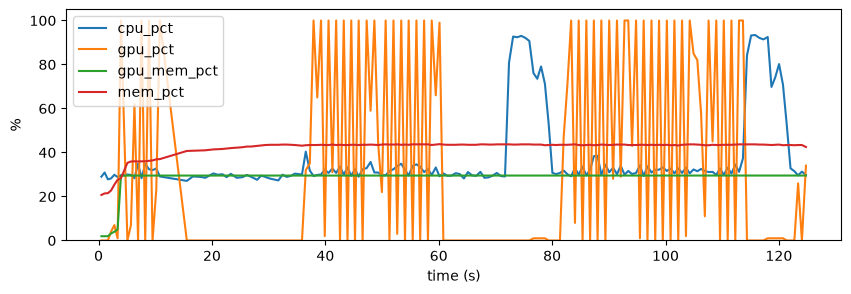

In [27]:
import base64, io, json, html
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

report = json.load(open(f"{local_dir}/rules.json"))
sysm = pd.read_csv(f"{local_dir}/system_metrics.csv")
torch_table = open(f"{local_dir}/torch_profiler_summary.txt").read()

def fig_to_img(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight"); plt.close(fig)
    return f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}"/>'

# System utilisation chart
fig, ax = plt.subplots(figsize=(10, 3))
for col in ["cpu_pct", "gpu_pct", "gpu_mem_pct", "mem_pct"]:
    if sysm[col].notna().any():
        ax.plot(sysm["time_s"], sysm[col], label=col)
ax.set_ylim(0, 105); ax.set_xlabel("time (s)"); ax.set_ylabel("%"); ax.legend()
sys_img = fig_to_img(fig)

# Recommendations for each triggered rule
advice = {
    "DataLoaderBottleneck": "Increase DataLoader num_workers (e.g. 4) and set pin_memory=True.",
    "LowGPUUtilization": "GPU is often idle: speed up data loading, or use a smaller/cheaper instance.",
    "LossNotDecreasing": "Lower the learning rate (e.g. 0.01-0.1).",
    "Overfit": "Validation loss >> training loss: check learning rate / BatchNorm, add regularization.",
    "Overtraining": "Validation loss stopped improving: use early stopping.",
    "VanishingGradient": "Check initialization, activation functions, learning rate.",
}
rows = "".join(
    f"<tr><td>{k}</td><td style='color:{'red' if v['triggered'] else 'green'}'>"
    f"{'TRIGGERED' if v['triggered'] else 'ok'}</td><td>{html.escape(v['detail'])}</td>"
    f"<td>{advice.get(k, '') if v['triggered'] else ''}</td></tr>"
    for k, v in report["rules"].items()
)
t = report["timing"]
stats = sysm.describe().loc[["mean", "50%", "max"]].round(1).to_html()

page = f"""<html><body style="font-family:sans-serif">
<h1>Profiler report - {training_job_name}</h1>
<h2>Rules summary</h2>
<table border=1 cellpadding=4><tr><th>Rule</th><th>Status</th><th>Detail</th><th>Recommendation</th></tr>{rows}</table>
<h2>Step time breakdown</h2>
<p>Data loading: {t['data_loading_s']:.1f}s | Compute: {t['compute_s']:.1f}s</p>
<h2>System utilisation</h2>{sys_img}{stats}
<h2>Top operators (torch.profiler)</h2><pre>{html.escape(torch_table)}</pre>
</body></html>"""

with open("profiler-report.html", "w") as f:
    f.write(page)
display(HTML(page))